# **Проектная работа №4. Анализ динамики изменений земного покрова на последовательности разновременных спутниковых снимков с использованием спектральных индексов**

## **1. Цель работы**

Выполнить количественный анализ динамики изменения классов земного покрова на выбранной территории за период с 2019 по 2024 год на основе разновременных спутниковых снимков Sentinel-2 и провести сравнительную оценку результатов, полученных методом пороговой сегментации на основе спектральных индексов и с использованием готовых карт классификации Dynamic World.

## **2. Задачи работы**

1.  **Подготовить** последовательность разновременных снимков (снимки Sentinel-2 и карты Dynamic World) за 2019-2024 гг.;
2.  **Классифицировать** земной покров на снимках Sentinel-2, применив метод пороговой сегментации по спектральным индексам;
3.  **Рассчитать и сравнить** количественные показатели динамики (площади, темпы роста) для двух методов классификации: по индексам и по данным Dynamic World;
4.  **Оценить** выявленные тренды изменения покрова и **сформулировать** выводы о сопоставимости результатов двух методов анализа.

## **3. Загрузка данных для анализа из Google Earth Engine**

> **Примечание.** В качестве примера реализации можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/nWdJIg. Для выполнения текущей работы актуальны только **Раздел 1** и **Раздел 2** указанного источника.





### **3.1. Настройка рабочей среды и аутентификация**

In [1]:
%pip install -q geemap geedim rasterio folium

import ee
import folium
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

from pathlib import Path
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from rasterio.plot import plotting_extent
from rasterio.warp import transform

ee.Authenticate()
ee.Initialize(project="image-processing-510810")


### **3.2. Определение области интереса**

- Выберите территорию размером не менее 10×10 км (100 км²) с разнообразным земным покровом
- Обязательно должны присутствовать: водные объекты, растительность, застройка, открытая почва
- Зафиксируйте координаты углов ROI для воспроизводимости результатов

In [2]:
crs = "EPSG:32639"
west, south, east, north = 371100, 6177400, 383100, 6189400
roi = ee.Geometry.Rectangle([west, south, east, north], crs, False)

years = list(range(2019, 2025))
scale = 10
roi_area_ha = (east - west) * (north - south) / 10000
longitude, latitude = transform(
    crs, "EPSG:4326", [west, east, east, west], [south, south, north, north]
)

print(f"Площадь участка: {roi_area_ha / 100:.2f} км²")
print("Углы участка (долгота, широта)")
for lon, lat in zip(longitude, latitude):
    print(f"{lon:.6f}, {lat:.6f}")

center = [np.mean(latitude), np.mean(longitude)]
roi_map = folium.Map(location=center, zoom_start=11)
folium.Polygon(
    locations=list(zip(latitude, longitude)), color="#c4281b", weight=3,
    fill=True, fill_opacity=0.1, tooltip="Запад Казани и долина Волги"
).add_to(roi_map)
display(roi_map)


Площадь участка: 144.00 км²
Углы участка (долгота, широта)
48.947608, 55.725165
49.138558, 55.728208
49.133411, 55.835974
48.941935, 55.832919


### **3.3. Функции для загрузки и обработки данных Sentinel-2**

In [3]:
bands = ["B2", "B3", "B4", "B8", "B11", "B12"]


def mask_clouds(image):
    scl = image.select("SCL")
    mask = scl.neq(0).And(scl.neq(1)).And(scl.neq(3))
    mask = mask.And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return image.select(bands).updateMask(mask).divide(10000).toFloat()


def load_sentinel2(roi, start_date, end_date):
    images = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    images = images.filterBounds(roi).filterDate(start_date, end_date)
    images = images.filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20))
    return images.map(mask_clouds)


### **3.4. Создание медианных композитов за летние периоды 2019-2024**

- Используйте медиану для минимизации влияния облачности
- Фильтрация по облачности: CLOUDY_PIXEL_PERCENTAGE < 20%
- Маскирование облаков и теней по каналу SCL (см. лекцию, раздел 2.2)


In [4]:
sentinel = {}
sentinel_counts = []

for year in years:
    images = load_sentinel2(roi, f"{year}-06-01", f"{year}-09-01")
    sentinel[year] = images.median().clip(roi)
    sentinel_counts.append(images.size())

display(pd.DataFrame({"Год": years, "Снимков Sentinel-2": ee.List(sentinel_counts).getInfo()}))


,Год,Снимков Sentinel-2
0,2019,9
1,2020,12
2,2021,16
3,2022,13
4,2023,8
5,2024,11


### **3.5. Функции для загрузки и обработки данных карт классификации**

**Используйте коллекцию Dynamic World (Google/WRI)**

**Коллекция в GEE:** `ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")`
- **Период:** с июня 2015 года по настоящее время (обновляется постоянно)
- **Разрешение:** 10 метров
- **Особенности:**
  - Предоставляет вероятности для каждого класса (не жесткую классификацию)
  - Обновляется почти в реальном времени для каждого снимка Sentinel-2
  - 9 классов земного покрова


```python
# Пример загрузки Dynamic World

def load_landcover_data(roi, start_date, end_date, composite='mode'):
    """
    Загружает карты классификации Google Dynamic World (10м).
    
    Классы: 0-Вода, 1-Деревья, 2-Трава, 3-Затопл.растительность,
            4-Культуры, 5-Кустарники, 6-Застройка, 7-Голая земля, 8-Снег/лед
    
    Args:
        roi: область интереса
        start_date, end_date: период 'YYYY-MM-DD'
        composite: 'mode'|'first'|'mosaic'|'collection'
    """
    
    labels = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1") \
        .filterBounds(roi) \
        .filterDate(start_date, end_date) \
        .select('label')
    
    if composite == 'collection':
        return labels.map(lambda img: img.clip(roi))
    
    return getattr(labels, composite)().clip(roi)

# Загрузка с композитом по моде (наиболее частый класс)
landcover = load_landcover_data(roi, '2024-06-01', '2024-08-31')

# Параметры визуализации для Dynamic World
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': [
        '419bdf',  # 0 - Вода - синий
        '397d49',  # 1 - Деревья - темно-зеленый  
        '88b053',  # 2 - Трава - светло-зеленый
        '7a87c6',  # 3 - Затопленная растительность - сине-фиолетовый
        'e49635',  # 4 - Культуры - оранжево-желтый
        'dfc35a',  # 5 - Кустарники - песочный
        'c4281b',  # 6 - Застройка - красный
        'a59b8f',  # 7 - Голая земля - серо-коричневый
        'b39fe1'   # 8 - Снег и лед - светло-фиолетовый (для контраста)
    ]
}

# Визуализация на карте
map_dw = geemap.Map()
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover, landcover_vis, 'Dynamic World')
map_dw

```

In [5]:
dw_names = [
    "Вода", "Деревья", "Трава", "Затопленная растительность",
    "Культуры", "Кустарники", "Застройка", "Голая земля", "Снег/лёд"
]
dw_colors = [
    "#419bdf", "#397d49", "#88b053", "#7a87c6", "#e49635",
    "#dfc35a", "#c4281b", "#a59b8f", "#b39fe1"
]


def load_landcover_data(roi, start_date, end_date):
    images = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    return images.filterBounds(roi).filterDate(start_date, end_date).select("label")


### **3.6. Создание карт классификации за летние периоды 2019-2024**

- Для карт классов используйте моду — наиболее частый класс в каждом пикселе (`composite='mode'`): медиана номеров классов не имеет смысла

In [6]:
dynamic_world = {}
dw_counts = []

for year in years:
    labels = load_landcover_data(roi, f"{year}-06-01", f"{year}-09-01")
    dynamic_world[year] = labels.mode().clip(roi).toInt16()
    dw_counts.append(labels.size())

display(pd.DataFrame({"Год": years, "Карт Dynamic World": ee.List(dw_counts).getInfo()}))


,Год,Карт Dynamic World
0,2019,26
1,2020,22
2,2021,31
3,2022,29
4,2023,23
5,2024,30


### **3.7. Экспорт полученных растров**

- **Медианные композиты** Sentinel-2 (6 файлов GeoTIFF):
  - `sentinel2_summer_2019.tif` (июнь-август 2019)
  - `sentinel2_summer_2020.tif` (июнь-август 2020)
  - `sentinel2_summer_2021.tif` (июнь-август 2021)
  - `sentinel2_summer_2022.tif` (июнь-август 2022)
  - `sentinel2_summer_2023.tif` (июнь-август 2023)
  - `sentinel2_summer_2024.tif` (июнь-август 2024)

- **Карты классификации** Dynamic World (6 файлов GeoTIFF):
  - `DYNAMICWORLD_summer_2019.tif` (июнь-август 2019)
  - `DYNAMICWORLD_summer_2020.tif` (июнь-август 2020)
  - `DYNAMICWORLD_summer_2021.tif` (июнь-август 2021)
  - `DYNAMICWORLD_summer_2022.tif` (июнь-август 2022)
  - `DYNAMICWORLD_summer_2023.tif` (июнь-август 2023)
  - `DYNAMICWORLD_summer_2024.tif` (июнь-август 2024)

- Экспорт выполняйте в метрической проекции UTM функцией `export_georeferenced_raster` из лекции: размер пикселя 10×10 м
- Карты Dynamic World экспортируйте с типом `int16`: при типе `uint8` значение 0 используется как «нет данных» и совпадает с классом «Вода»
- Размер пикселя 10 м соответствует собственному разрешению каналов B2, B3, B4 и B8; каналы B11 и B12 (20 м) при экспорте пересчитываются на ту же сетку. Если экспорт идёт слишком долго, увеличьте `scale` (например, до 20 или 30 м): площади в разделе 6 рассчитываются по размеру пикселя из растра

In [7]:
data_dir = Path("rasters")
data_dir.mkdir(exist_ok=True)

sentinel_nodata = -9999
dw_nodata = -32768


def export_georeferenced_raster(image, filename, dtype, nodata):
    grid = [scale, 0, west, 0, -scale, north]
    shape = ((north - south) // scale, (east - west) // scale)
    geemap.download_ee_image(
        image, str(filename), crs=crs, crs_transform=grid, shape=shape,
        dtype=dtype, unmask_value=nodata, nodata=nodata, max_tile_dim=600
    )
    print(f"Сохранён {filename.name}")


for year in years:
    export_georeferenced_raster(
        sentinel[year], data_dir / f"sentinel2_summer_{year}.tif", "float32", sentinel_nodata
    )
    export_georeferenced_raster(
        dynamic_world[year], data_dir / f"DYNAMICWORLD_summer_{year}.tif", "int16", dw_nodata
    )


Сохранён sentinel2_summer_2019.tif
Сохранён DYNAMICWORLD_summer_2019.tif
Сохранён sentinel2_summer_2020.tif
Сохранён DYNAMICWORLD_summer_2020.tif
Сохранён sentinel2_summer_2021.tif
Сохранён DYNAMICWORLD_summer_2021.tif
Сохранён sentinel2_summer_2022.tif
Сохранён DYNAMICWORLD_summer_2022.tif
Сохранён sentinel2_summer_2023.tif
Сохранён DYNAMICWORLD_summer_2023.tif
Сохранён sentinel2_summer_2024.tif
Сохранён DYNAMICWORLD_summer_2024.tif


## **4. Работа с загруженными растрами в RasterIO**

### **4.1. Загрузка и проверка растров**

Sentinel-2 за 2024 год · EPSG:32639
Размер растра: 1200 × 1200 пикселей
Размер пикселя: 10 × 10 м
Границы UTM: 371100, 6.1774e+06, 383100, 6.1894e+06
Каналы: B2, B3, B4, B8, B11, B12


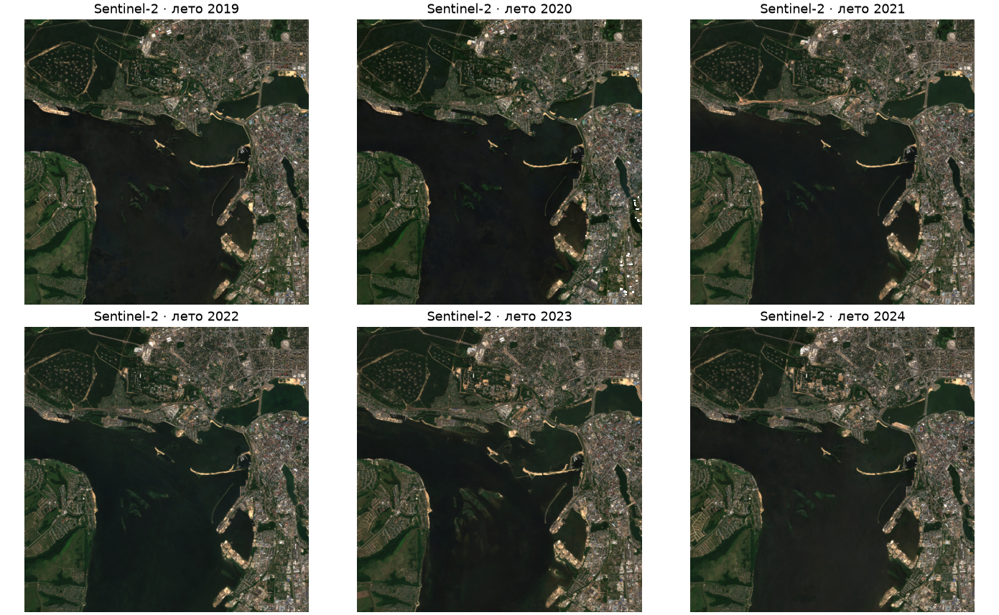

In [8]:
sentinel_paths = {}
reflectance = {}
profiles = {}
extents = {}

for year in years:
    sentinel_paths[year] = data_dir / f"sentinel2_summer_{year}.tif"

with rasterio.open(sentinel_paths[2024]) as src:
    print(f"Sentinel-2 за 2024 год · {src.crs}")
    print(f"Размер растра: {src.width} × {src.height} пикселей")
    print(f"Размер пикселя: {src.res[0]:g} × {src.res[1]:g} м")
    print(f"Границы UTM: {src.bounds.left:g}, {src.bounds.bottom:g}, "
          f"{src.bounds.right:g}, {src.bounds.top:g}")
    print("Каналы:", ", ".join(bands))

fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout="constrained")

for ax, year in zip(axes.flat, years):
    with rasterio.open(sentinel_paths[year]) as src:
        data = src.read(masked=True).astype("float32").filled(np.nan)
        data[data == sentinel_nodata] = np.nan
        reflectance[year] = data
        profiles[year] = src.profile
        extents[year] = plotting_extent(src)

    rgb = np.dstack((data[2], data[1], data[0]))
    ax.imshow(np.clip(rgb / 0.30, 0, 1), extent=extents[year])
    ax.set_title(f"Sentinel-2 · лето {year}")
    ax.axis("off")

plt.show()


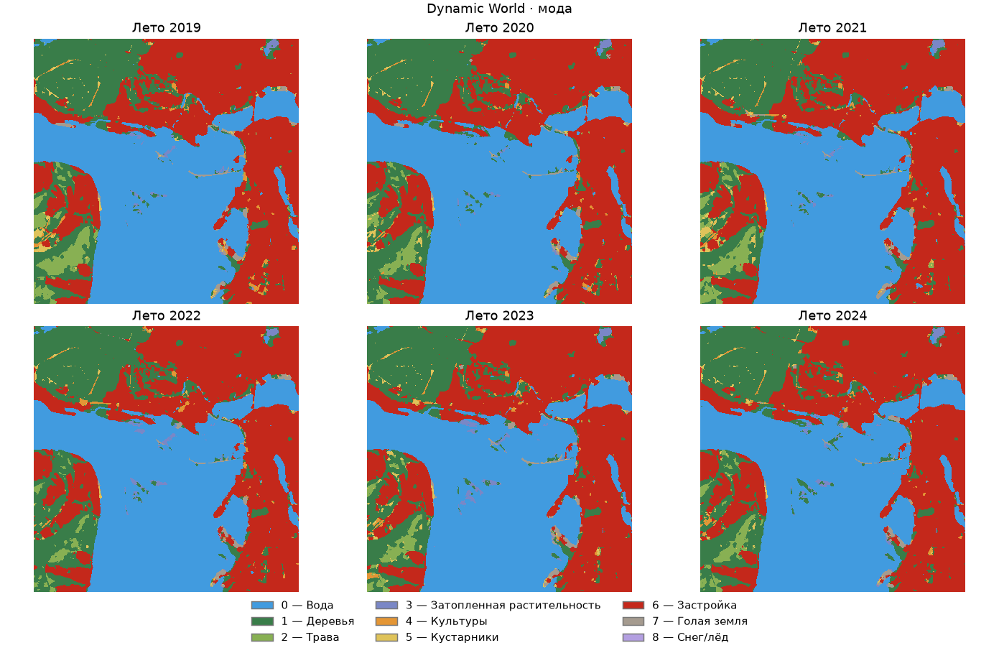

In [9]:
dw_paths = {}
dw_maps = {}
dw_extents = {}

for year in years:
    path = data_dir / f"DYNAMICWORLD_summer_{year}.tif"
    dw_paths[year] = path
    with rasterio.open(path) as src:
        dw_maps[year] = src.read(1, masked=True).filled(dw_nodata)
        dw_extents[year] = plotting_extent(src)


def plot_classes(maps, extents, names, colors, nodata, title, legend_columns):
    cmap = ListedColormap(colors)
    cmap.set_bad("#e6edf2")
    fig, axes = plt.subplots(2, 3, figsize=(13, 8.5), layout="constrained")
    fig.suptitle(title)

    for ax, year in zip(axes.flat, years):
        raster = np.ma.masked_equal(maps[year], nodata)
        ax.imshow(raster, cmap=cmap, vmin=-0.5, vmax=len(names) - 0.5,
                  interpolation="nearest", extent=extents[year])
        ax.set_title(f"Лето {year}")
        ax.axis("off")

    handles = []
    for label, (name, color) in enumerate(zip(names, colors)):
        handles.append(Patch(facecolor=color, edgecolor="#777777", label=f"{label} — {name}"))
    fig.legend(handles=handles, loc="outside lower center", ncols=legend_columns, frameon=False)
    plt.show()


plot_classes(dw_maps, dw_extents, dw_names, dw_colors, dw_nodata, "Dynamic World · мода", 3)


### **4.2. Рассчитать все 8 индексов для каждого года (2019-2024)**


> **Примечание.** В качестве примера рассчета индексов можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/4qBeIg





**Спектральные индексы** — это математические комбинации значений отражения в разных спектральных каналах, позволяющие выделить определенные типы объектов.








#### **Таблица 1. Основные спектральные индексы для анализа земного покрова**




| **Индекс** | **Формула** | **Назначение** | **Каналы Sentinel-2** |
|------------|-------------|----------------|------------------------|
| **NDVI** (Normalized Difference Vegetation Index) | (NIR - RED) / (NIR + RED) | Оценка состояния растительности | (B8 - B4) / (B8 + B4) |
| **NDWI** (Normalized Difference Water Index) | (GREEN - NIR) / (GREEN + NIR) | Выделение водных объектов | (B3 - B8) / (B3 + B8) |
| **NDBI** (Normalized Difference Built-up Index) | (SWIR - NIR) / (SWIR + NIR) | Выделение застроенных территорий | (B11 - B8) / (B11 + B8) |
| **SAVI** (Soil Adjusted Vegetation Index) | ((NIR - RED) / (NIR + RED + L)) * (1 + L), L=0.5 | Растительность с учетом почвы | ((B8 - B4) / (B8 + B4 + 0.5)) * 1.5 |
| **EVI** (Enhanced Vegetation Index) | 2.5 * ((NIR - RED) / (NIR + 6*RED - 7.5*BLUE + 1)) | Улучшенный вегетационный индекс | 2.5 * ((B8 - B4) / (B8 + 6*B4 - 7.5*B2 + 1)) |
| **MNDWI** (Modified NDWI) | (GREEN - SWIR) / (GREEN + SWIR) | Модифицированный водный индекс | (B3 - B11) / (B3 + B11) |
| **BSI** (Bare Soil Index) | ((SWIR + RED) - (NIR + BLUE)) / ((SWIR + RED) + (NIR + BLUE)) | Открытая почва | ((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2)) |
| **NDSI** (Normalized Difference Snow Index) | (GREEN - SWIR) / (GREEN + SWIR) | Снежный покров | (B3 - B11) / (B3 + B11) |

NDSI и MNDWI вычисляются по одной формуле, поэтому высокие значения дают и снег, и вода. Снег отличается от воды высоким отражением в ближнем ИК-канале (B8 > 0.11), а вода ИК-излучение поглощает.


#### **Таблица 2. Интерпретация значений NDVI**



| **Диапазон NDVI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| < 0.0 | Вода | Водные поверхности, снег |
| 0.0 - 0.1 | Открытая почва | Песок, камни, бетон |
| 0.1 - 0.2 | Разреженная растительность | Степи, пустыни |
| 0.2 - 0.4 | Умеренная растительность | Кустарники, луга |
| 0.4 - 0.6 | Плотная растительность | Лиственные леса |
| > 0.6 | Очень плотная растительность | Тропические леса, хвойные леса |

#### **Таблица 3. Интерпретация значений NDWI**



| **Диапазон NDWI** | **Тип объекта** | **Описание** |
|-------------------|-----------------|--------------|
| > 0.3 | Водные объекты | Реки, озера, пруды |
| 0.0 - 0.3 | Влажная почва/растительность | Болота, заливные луга |
| -0.3 - 0.0 | Сухая растительность | Обычная растительность |
| < -0.3 | Застройка/почва | Городская застройка, открытая почва |

#### **Таблица 4. Интерпретация значений NDBI**



| **Диапазон NDBI** | **Тип территории** | **Характеристика** |
|-------------------|-------------------|---------------------|
| > 0.0 | Застроенные территории | Города, промзоны |
| -0.1 - 0.0 | Смешанные территории | Пригороды, села |
| < -0.1 | Природные территории | Леса, поля, водоемы |

#### **Таблица 5. Интерпретация значений SAVI**



| **Диапазон SAVI** | **Тип покрова** | **Описание** |
|-------------------|-----------------|---------------|
| < 0.1 | Открытая почва/вода | Водные объекты, голая почва |
| 0.1 - 0.2 | Очень разреженная растительность | Пустыни, каменистые участки |
| 0.2 - 0.4 | Разреженная растительность | Степи, саванны |
| 0.4 - 0.6 | Умеренная растительность | Сельхозугодья, луга |
| > 0.6 | Плотная растительность | Леса, густые кустарники |

#### **Таблица 6. Интерпретация значений EVI**



| **Диапазон EVI** | **Состояние растительности** | **Характеристика** |
|------------------|------------------------------|---------------------|
| < 0.0 | Нет растительности | Вода, снег, облака |
| 0.0 - 0.2 | Минимальная растительность | Голая почва, урбанизированные территории |
| 0.2 - 0.3 | Низкая биомасса | Травянистая растительность |
| 0.3 - 0.5 | Средняя биомасса | Кустарники, молодые посевы |
| 0.5 - 0.8 | Высокая биомасса | Зрелые леса, интенсивное сельское хозяйство |
| > 0.8 | Очень высокая биомасса | Тропические леса |

#### **Таблица 7. Интерпретация значений MNDWI**



| **Диапазон MNDWI** | **Тип объекта** | **Характеристика** |
|--------------------|-----------------|---------------------|
| > 0.5 | Глубокая вода | Озера, моря, водохранилища |
| 0.2 - 0.5 | Мелкая вода | Реки, каналы, мелководья |
| 0.0 - 0.2 | Влажные территории | Болота, рисовые поля |
| < 0.0 | Суша | Растительность, почва, застройка |

#### **Таблица 8. Интерпретация значений BSI**



| **Диапазон BSI** | **Тип поверхности** | **Описание** |
|-------------------|-------------------|---------------|
| > 0.1 | Открытая почва | Пашни, карьеры, пустыни |
| 0.0 - 0.1 | Частично покрытая почва | Разреженная растительность |
| -0.1 - 0.0 | Смешанный покров | Переходные зоны |
| < -0.1 | Растительность/вода | Леса, водоемы, плотная растительность |

#### **Таблица 9. Интерпретация значений NDSI**



| **Диапазон NDSI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| > 0.4 | Снежный покров | Чистый снег, ледники |
| 0.2 - 0.4 | Частичный снежный покров | Смешанный снег с растительностью |
| 0.0 - 0.2 | Возможный снег/лед | Тающий снег, иней, облака |
| -0.2 - 0.0 | Переходная зона | Влажная почва, туман |
| < -0.2 | Бесснежные территории | Растительность, почва, вода |

In [10]:
def ratio(numerator, denominator):
    result = np.full(numerator.shape, np.nan, dtype="float32")
    np.divide(numerator, denominator, out=result, where=denominator != 0)
    return result


def calculate_indices(data):
    blue, green, red, nir, swir, _ = data
    ndvi = ratio(nir - red, nir + red)
    ndwi = ratio(green - nir, green + nir)
    ndbi = ratio(swir - nir, swir + nir)
    savi = 1.5 * ratio(nir - red, nir + red + 0.5)
    evi = 2.5 * ratio(nir - red, nir + 6 * red - 7.5 * blue + 1)
    mndwi = ratio(green - swir, green + swir)
    bsi = ratio(swir + red - nir - blue, swir + red + nir + blue)
    ndsi = mndwi.copy()
    return {
        "NDVI": ndvi, "NDWI": ndwi, "NDBI": ndbi, "SAVI": savi,
        "EVI": evi, "MNDWI": mndwi, "BSI": bsi, "NDSI": ndsi
    }


indices = {}
for year in years:
    indices[year] = calculate_indices(reflectance[year])
    ndvi = indices[year]["NDVI"]
    print(f"{year} · индексов: {len(indices[year])}, средний NDVI: {np.nanmean(ndvi):.3f}, "
          f"минимум: {np.nanmin(ndvi):.3f}, максимум: {np.nanmax(ndvi):.3f}")


2019 · индексов: 8, средний NDVI: 0.289, минимум: -0.409, максимум: 0.959
2020 · индексов: 8, средний NDVI: 0.278, минимум: -0.499, максимум: 0.948
2021 · индексов: 8, средний NDVI: 0.250, минимум: -0.454, максимум: 0.924
2022 · индексов: 8, средний NDVI: 0.252, минимум: -0.568, максимум: 0.936
2023 · индексов: 8, средний NDVI: 0.236, минимум: -0.502, максимум: 0.917
2024 · индексов: 8, средний NDVI: 0.268, минимум: -0.513, максимум: 0.938


### **4.3. Визуализировать каждый индекс для 2024 года с соответствующей цветовой шкалой**



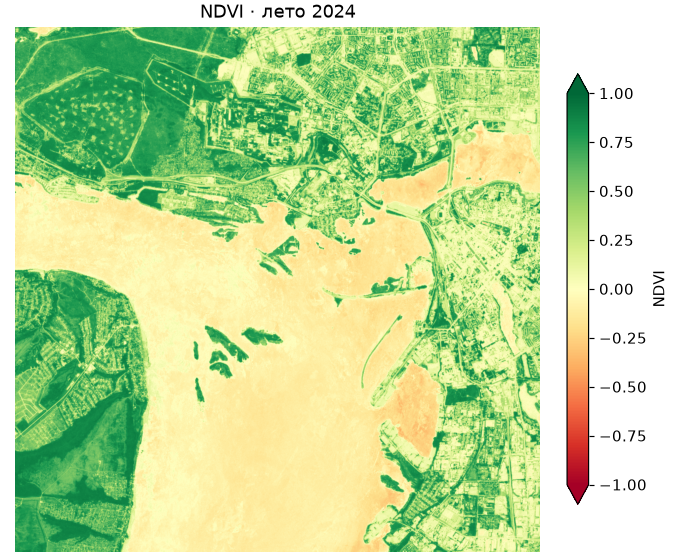

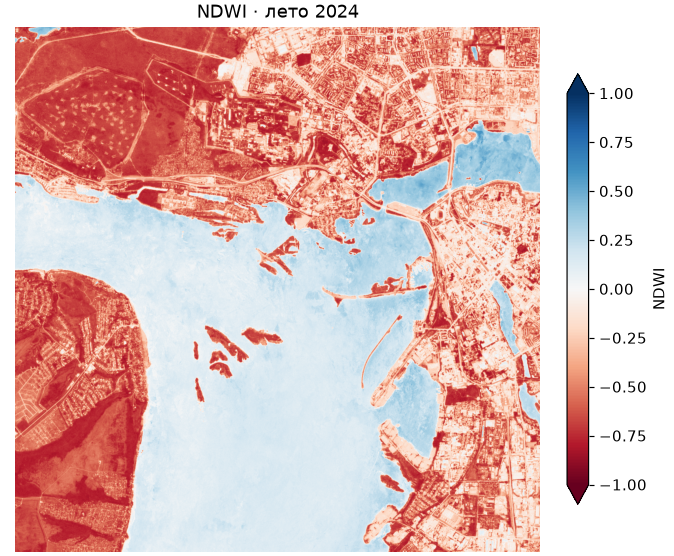

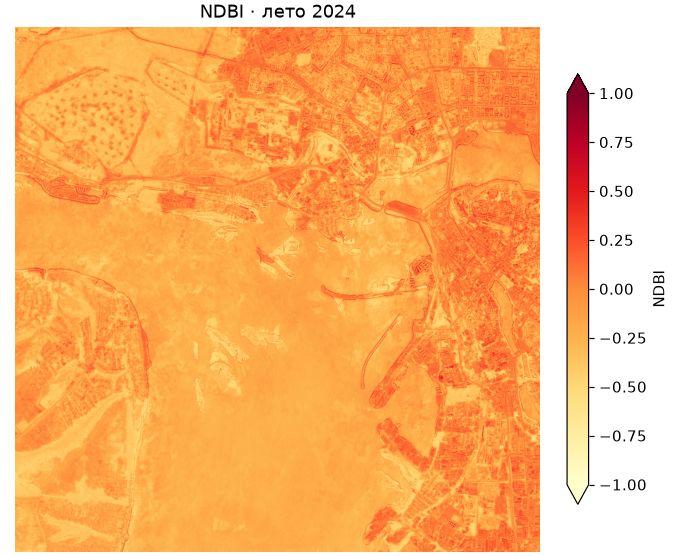

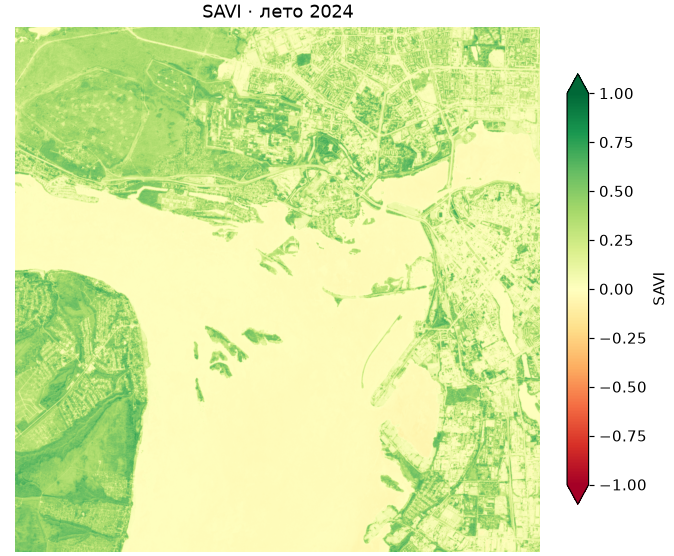

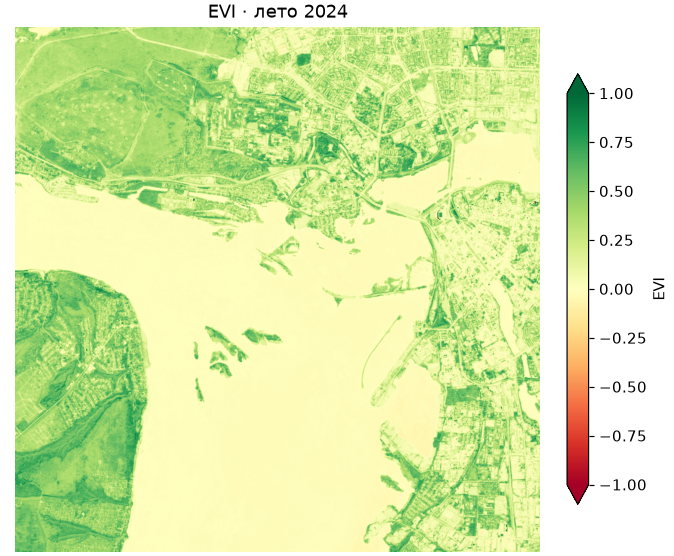

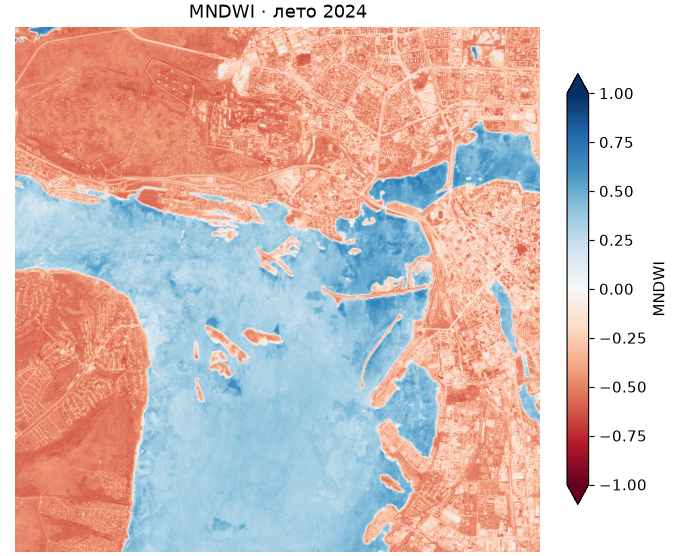

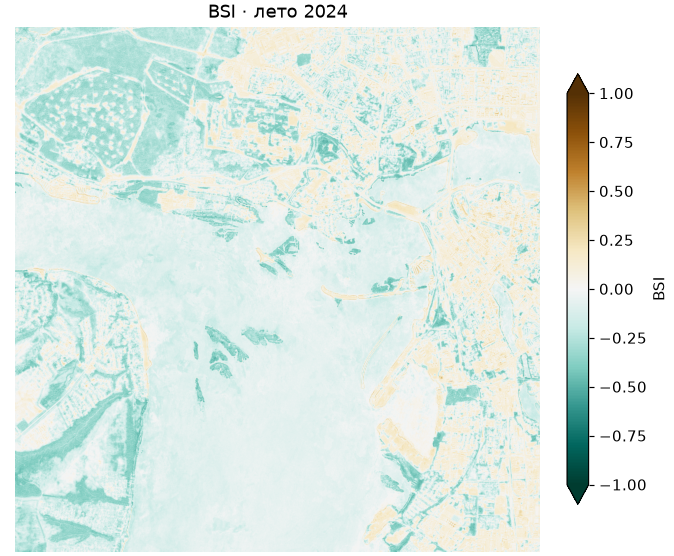

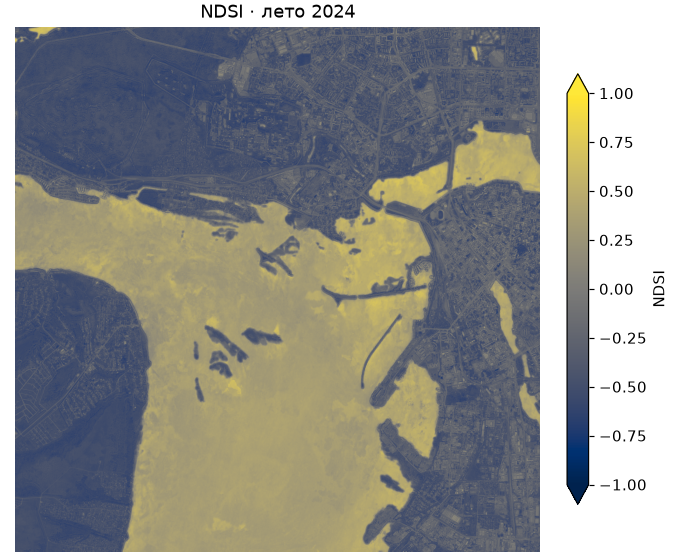

In [11]:
index_colors = {
    "NDVI": "RdYlGn", "NDWI": "RdBu", "NDBI": "YlOrRd", "SAVI": "RdYlGn",
    "EVI": "RdYlGn", "MNDWI": "RdBu", "BSI": "BrBG_r", "NDSI": "cividis"
}

for name, values in indices[2024].items():
    fig, ax = plt.subplots(figsize=(6.3, 5.2), layout="constrained")
    image = ax.imshow(values, cmap=index_colors[name], vmin=-1, vmax=1, extent=extents[2024])
    ax.set_title(f"{name} · лето 2024")
    ax.axis("off")
    fig.colorbar(image, ax=ax, label=name, shrink=0.82, extend="both")
    plt.show()


### **4.4. Сохранить все рассчитанные индексы в отдельные GeoTIFF файлы с сохранением геопривязки (сохранить в соответствующие папки по годам)**



In [12]:
for year in years:
    year_dir = Path("indices") / str(year)
    year_dir.mkdir(parents=True, exist_ok=True)

    profile = profiles[year].copy()
    profile.update(count=1, dtype="float32", nodata=np.nan)
    for name, values in indices[year].items():
        with rasterio.open(year_dir / f"{name}_{year}.tif", "w", **profile) as dst:
            dst.write(values, 1)

print(f"Сохранено {len(years) * len(indices[2024])} GeoTIFF в папке indices.")


Сохранено 48 GeoTIFF в папке indices.


## **5. Сегментация и классификация**

**Сегментация** — процесс разделения изображения на однородные регионы (сегменты) на основе заданных критериев .


### **5.1. Многопороговая сегментация с использованием спектральных индексов**



**Задание:** Реализовать классификацию земного покрова путем замены значений пикселей в растрах индексов на метки классов согласно пороговым правилам.

**Пояснение:** По сути необходимо преобразовать непрерывные значения индексов в дискретные классы (метки) на основе пороговых значений из Таблиц 2-9. Каждому пикселю присваивается числовая метка класса (0-7) в зависимости от значений спектральных индексов.






**Алгоритм многопороговой сегментации:**
1. Создать пустой растр для меток классов (заполнить значением -1 или 255 для "неклассифицировано")
2. Последовательно применить правила классификации
3. Каждое правило проверяется только для еще не классифицированных пикселей
4. Присвоить соответствующую метку класса пикселям, удовлетворяющим условию

**Иерархия правил классификации (применять строго последовательно):**
1. **Снег/лед (метка=1)**: (NDSI > 0.4) И (B8 > 0.11)
2. **Вода (метка=0)**: ((NDWI > 0.3) ИЛИ (MNDWI > 0.2)) И (еще не классифицировано)
3. **Застройка (метка=2)**: (NDBI > 0.0) И (NDVI < 0.2) И (еще не классифицировано)
4. **Густая растительность (метка=3)**: ((NDVI > 0.6) ИЛИ (EVI > 0.5)) И (еще не классифицировано)
5. **Умеренная растительность (метка=4)**: (0.3 ≤ NDVI ≤ 0.6) И (еще не классифицировано)
6. **Разреженная растительность (метка=5)**: (0.1 ≤ NDVI < 0.3) И (еще не классифицировано)
7. **Открытая почва (метка=6)**: (BSI > 0.0) И (NDVI < 0.1) И (еще не классифицировано)
8. **Прочее (метка=7)**: все оставшиеся неклассифицированные пиксели

**Обратите внимание:** открытая почва и пашня, как и застройка, дают NDBI > 0, поэтому правило 3 относит часть открытой почвы к застройке. Учитывайте это при интерпретации результатов и сравнении с Dynamic World.


**(МОЖЕТЕ СФОРМУЛИРОВАТЬ СВОИ ПРАВИЛА, ОСНОВЫВАЯСЬ НА ТАБЛИЦАХ, ПРИВЕДЕННЫХ ВЫШЕ!)**

In [13]:
class_names = [
    "Вода", "Снег/лёд", "Застройка", "Густая растительность",
    "Умеренная растительность", "Разреженная растительность", "Открытая почва", "Прочее"
]
class_colors = [
    "#419bdf", "#ffffff", "#c4281b", "#397d49", "#88b053",
    "#c6e48b", "#a59b8f", "#808080"
]
class_nodata = 255


def segment(index, nir):
    ndsi = index["NDSI"]
    ndwi = index["NDWI"]
    mndwi = index["MNDWI"]
    ndvi = index["NDVI"]
    ndbi = index["NDBI"]
    evi = index["EVI"]
    bsi = index["BSI"]

    valid = np.isfinite(nir) & np.isfinite(ndvi) & np.isfinite(ndwi)
    valid = valid & np.isfinite(mndwi) & np.isfinite(ndbi) & np.isfinite(bsi)
    labels = np.full(nir.shape, class_nodata, dtype="uint8")
    rules = [
        (1, (ndsi > 0.4) & (nir > 0.11)),
        (0, (ndwi > 0.3) | (mndwi > 0.2)),
        (2, (ndbi > 0) & (ndvi < 0.2)),
        (3, (ndvi > 0.6) | (evi > 0.5)),
        (4, (ndvi >= 0.3) & (ndvi <= 0.6)),
        (5, (ndvi >= 0.1) & (ndvi < 0.3)),
        (6, (bsi > 0) & (ndvi < 0.1))
    ]
    for label, condition in rules:
        labels[valid & (labels == class_nodata) & condition] = label
    labels[valid & (labels == class_nodata)] = 7
    return labels


classes_2024 = segment(indices[2024], reflectance[2024][3])
print(f"Размер растра меток: {classes_2024.shape[1]} × {classes_2024.shape[0]}")
print("Метки в растре за 2024 год:", np.unique(classes_2024))


Размер растра меток: 1200 × 1200
Метки в растре за 2024 год: [0 1 2 3 4 5 6 7]



### **5.2. Подсчет количества пикселей каждого класса**



**Задание:** После замены значений индексов на метки классов, подсчитать количество пикселей для каждой метки класса.

**Пояснение:** Используйте функции numpy.unique() или аналогичные для подсчета количества пикселей с каждой меткой. Это позволит получить статистику распределения классов на изображении.

**Что нужно получить:**
- Массив уникальных меток классов (0-7)
- Количество пикселей для каждой метки
- Процентное соотношение классов от общего числа пикселей

In [14]:
def count_pixels(raster, names, nodata):
    labels, counts = np.unique(raster, return_counts=True)
    valid_total = counts[labels != nodata].sum()
    rows = []

    for label, count in zip(labels, counts):
        if label == nodata:
            rows.append([label, "Нет данных", count, np.nan])
        else:
            rows.append([label, names[label], count, count / valid_total * 100])

    columns = ["Метка", "Класс", "Пикселей", "Доля учтённых пикселей, %"]
    return pd.DataFrame(rows, columns=columns)


print(f"Пикселей в растре сегментации за 2024 год: {classes_2024.size:,}".replace(",", " "))
display(count_pixels(classes_2024, class_names, class_nodata).round(3))


Пикселей в растре сегментации за 2024 год: 1 440 000


,Метка,Класс,Пикселей,"Доля учтённых пикселей, %"
0,0,Вода,538032,37.363
1,1,Снег/лёд,11,0.001
2,2,Застройка,164510,11.424
3,3,Густая растительность,391354,27.177
4,4,Умеренная растительность,234125,16.259
5,5,Разреженная растительность,94303,6.549
6,6,Открытая почва,9632,0.669
7,7,Прочее,8033,0.558


### **5.3. Применение сегментации ко всем временным срезам**




**Задание:** Применить разработанный алгоритм сегментации ко всем медианным композитам (2019-2024).

**Пояснение:** Использовать одинаковые пороговые значения для всех лет для обеспечения сопоставимости результатов при анализе динамики. Сохранить результаты сегментации как растры с метками классов.

**Выходные данные:**
- 6 растров с метками классов (по одному на каждый год)
- Таблица с количеством пикселей каждого класса для каждого года
- Формат сохранения: GeoTIFF с сохранением геопривязки

In [15]:
class_dir = Path("classification")
class_dir.mkdir(exist_ok=True)
class_maps = {}
class_paths = {}
class_pixel_counts = pd.DataFrame(index=class_names).rename_axis("Класс")

for year in years:
    raster = segment(indices[year], reflectance[year][3])
    class_maps[year] = raster
    valid = raster != class_nodata
    class_pixel_counts[year] = np.bincount(raster[valid], minlength=len(class_names))

    profile = profiles[year].copy()
    profile.update(count=1, dtype="uint8", nodata=class_nodata)
    path = class_dir / f"classification_{year}.tif"
    class_paths[year] = path
    with rasterio.open(path, "w", **profile) as dst:
        dst.write(raster, 1)

print("Количество пикселей по классам и годам")
display(class_pixel_counts)


Количество пикселей по классам и годам


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,532214,529390,549361,551597,536690,538032
Снег/лёд,13,14,19,13,63,11
Застройка,142542,148398,164335,162411,177169,164510
Густая растительность,416978,426254,373735,410963,361914,391354
Умеренная растительность,232064,221346,247552,216784,252929,234125
Разреженная растительность,88972,89111,90196,85702,96912,94303
Открытая почва,9484,11020,9198,7956,9354,9632
Прочее,17733,14243,5604,4574,4969,8033


### **5.4. Визуализация результатов сегментации**






**Задание:** Создать тематические карты классификации с легендой.

**Пояснение:** Назначить каждой метке класса соответствующий цвет для визуализации. Использовать стандартную цветовую схему для классов земного покрова.

**Цветовая схема для визуализации:**
- 0 - Вода: синий (#419bdf)
- 1 - Снег/лед: белый (#ffffff)  
- 2 - Застройка: красный (#c4281b)
- 3 - Густая растительность: темно-зеленый (#397d49)
- 4 - Умеренная растительность: зеленый (#88b053)
- 5 - Разреженная растительность: светло-зеленый (#c6e48b)
- 6 - Открытая почва: коричневый (#a59b8f)
- 7 - Прочее: серый (#808080)

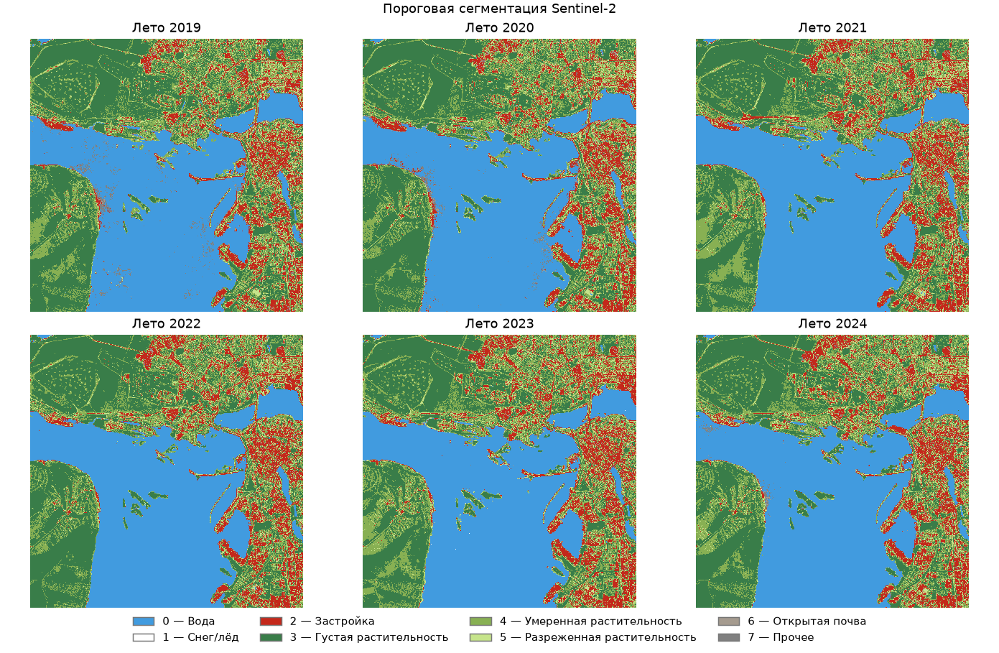

In [16]:
plot_classes(class_maps, extents, class_names, class_colors, class_nodata,
             "Пороговая сегментация Sentinel-2", 4)


## **6. Анализ динамики изменений на сегментированных растрах**

### **6.1. Рассчитать площади всех классов для каждого года**



**Формула перевода пикселей в площадь:**
```
Площадь (га) = Количество_пикселей × (Разрешение_м)² / 10000
Площадь (км²) = Количество_пикселей × (Разрешение_м)² / 1000000
```
Для Sentinel-2: разрешение = 10 м, следовательно:
- 1 пиксель = 100 м² = 0.01 га
- 100 пикселей = 1 га
- 10000 пикселей = 1 км²

Формула верна для растров в метрической проекции (UTM), где размер пикселя задан в метрах; размер пикселя берите из растра (`src.res`).

In [17]:
def pixel_area_m2(path):
    with rasterio.open(path) as src:
        dx, dy = src.res
    return dx * dy


def areas_from_counts(counts, paths):
    areas = counts.astype(float)
    for year in years:
        areas[year] = counts[year] * pixel_area_m2(paths[year]) / 10000
    return areas


def show_areas(areas):
    print("Площади классов, га")
    display(areas.round(2))
    print("Площади классов, км²")
    display((areas / 100).round(4))
    print("Доля от площади участка, %")
    display((areas / roi_area_ha * 100).round(3))


areas_ha = areas_from_counts(class_pixel_counts, class_paths)
print(f"Площадь одного пикселя: {pixel_area_m2(class_paths[2019]):g} м²")
show_areas(areas_ha)


Площадь одного пикселя: 100 м²
Площади классов, га


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,5322.14,5293.90,5493.61,5515.97,5366.90,5380.32
Снег/лёд,0.13,0.14,0.19,0.13,0.63,0.11
Застройка,1425.42,1483.98,1643.35,1624.11,1771.69,1645.10
Густая растительность,4169.78,4262.54,3737.35,4109.63,3619.14,3913.54
Умеренная растительность,2320.64,2213.46,2475.52,2167.84,2529.29,2341.25
Разреженная растительность,889.72,891.11,901.96,857.02,969.12,943.03
Открытая почва,94.84,110.20,91.98,79.56,93.54,96.32
Прочее,177.33,142.43,56.04,45.74,49.69,80.33


Площади классов, км²


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,53.2214,52.9390,54.9361,55.1597,53.6690,53.8032
Снег/лёд,0.0013,0.0014,0.0019,0.0013,0.0063,0.0011
Застройка,14.2542,14.8398,16.4335,16.2411,17.7169,16.4510
Густая растительность,41.6978,42.6254,37.3735,41.0963,36.1914,39.1354
Умеренная растительность,23.2064,22.1346,24.7552,21.6784,25.2929,23.4125
Разреженная растительность,8.8972,8.9111,9.0196,8.5702,9.6912,9.4303
Открытая почва,0.9484,1.1020,0.9198,0.7956,0.9354,0.9632
Прочее,1.7733,1.4243,0.5604,0.4574,0.4969,0.8033


Доля от площади участка, %


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,36.959,36.763,38.150,38.305,37.270,37.363
Снег/лёд,0.001,0.001,0.001,0.001,0.004,0.001
Застройка,9.899,10.305,11.412,11.279,12.303,11.424
Густая растительность,28.957,29.601,25.954,28.539,25.133,27.177
Умеренная растительность,16.116,15.371,17.191,15.054,17.565,16.259
Разреженная растительность,6.179,6.188,6.264,5.952,6.730,6.549
Открытая почва,0.659,0.765,0.639,0.552,0.650,0.669
Прочее,1.231,0.989,0.389,0.318,0.345,0.558


### **6.2. Построить графики динамики изменений для каждого класса**



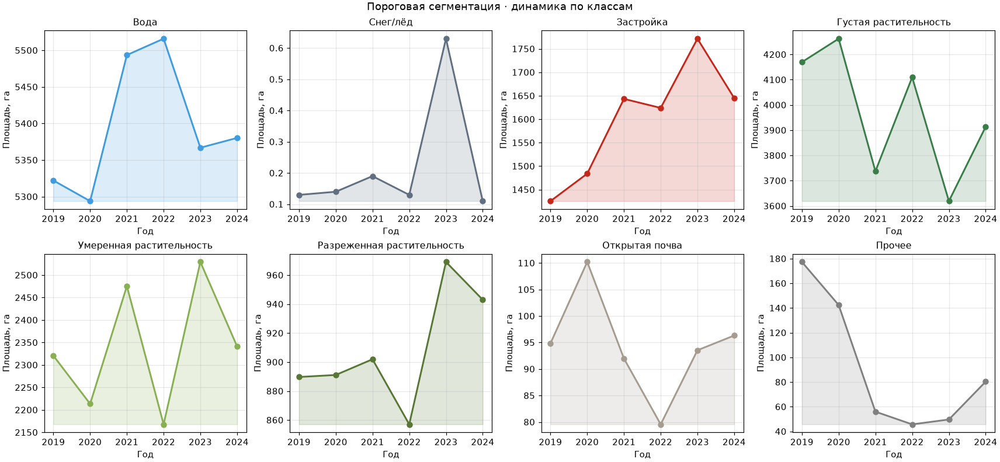

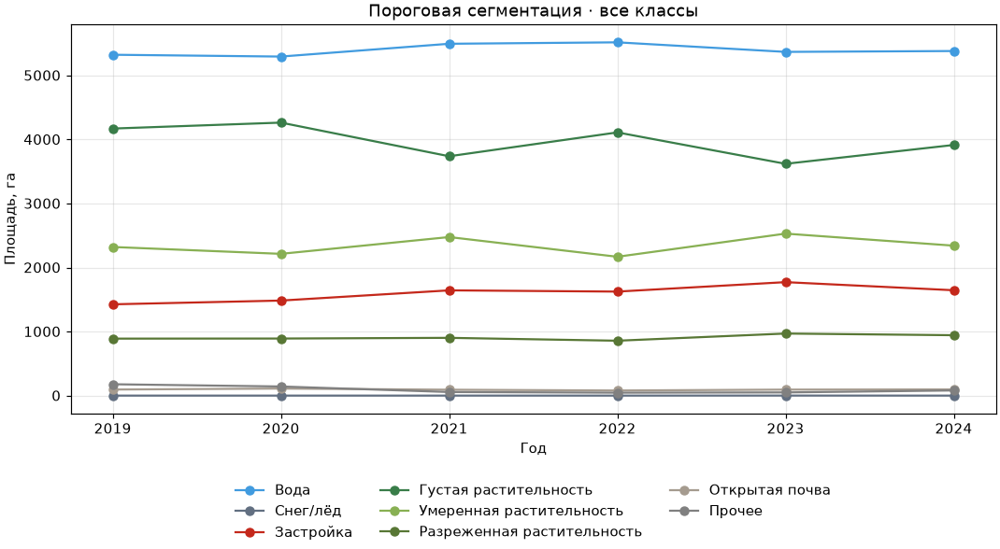

In [18]:
line_colors = {
    "#ffffff": "#626f81", "#c6e48b": "#587735", "#b39fe1": "#76549d",
    "#e49635": "#a7591a", "#dfc35a": "#927123"
}


def plot_dynamics(areas, colors, method, columns):
    nrows = (len(areas) + columns - 1) // columns
    fig, axes = plt.subplots(nrows, columns, figsize=(4 * columns, 3.7 * nrows),
                             layout="constrained")
    fig.suptitle(f"{method} · динамика по классам")

    for ax, name, color in zip(axes.flat, areas.index, colors):
        color = line_colors.get(color, color)
        values = areas.loc[name].to_numpy()
        ax.plot(years, values, "-o", color=color, linewidth=2)
        ax.fill_between(years, values.min(), values, color=color, alpha=0.18)
        ax.set_title(name, fontsize=11)
        ax.set_xlabel("Год")
        ax.set_ylabel("Площадь, га")
        ax.set_xticks(years)
        ax.ticklabel_format(axis="y", style="plain", useOffset=False)
        ax.grid(alpha=0.3)

    for ax in list(axes.flat)[len(areas):]:
        ax.axis("off")
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
    for name, color in zip(areas.index, colors):
        ax.plot(years, areas.loc[name], "-o", color=line_colors.get(color, color), label=name)

    ax.set_title(f"{method} · все классы")
    ax.set_xlabel("Год")
    ax.set_ylabel("Площадь, га")
    ax.set_xticks(years)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=3, frameon=False)
    plt.show()


plot_dynamics(areas_ha, class_colors, "Пороговая сегментация", 4)


### **6.3. Рассчитать все статистические показатели**



**Обязательные метрики для каждого класса:**

1. **Абсолютные показатели:**
   - Площадь в га и км² для каждого года
   - Количество пикселей
   - Процент от общей площади ROI

2. **Показатели изменений:**
   - Абсолютное изменение площади (га): ΔS = S₂₀₂₄ - S₂₀₁₉
   - Относительное изменение (%): (S₂₀₂₄ - S₂₀₁₉) / S₂₀₁₉ × 100%
   - Среднегодовой прирост (га/год): ΔS / количество_лет (2024 - 2019 = 5)
   - Среднегодовой темп роста (%/год): ((S₂₀₂₄/S₂₀₁₉)^(1/5) - 1) × 100%

3. **Статистика временного ряда:**
   - Коэффициент вариации: CV = σ/μ × 100% (вспомните материал прошлого семестра, а именно работу в numpy)
   - Стандартное отклонение площадей
   - Наклон линейного тренда площади (га/год) и коэффициент детерминации R² (`np.polyfit`)

In [19]:
def calculate_changes(areas):
    interval = years[-1] - years[0]
    x = np.array(years) - years[0]
    start = areas[years[0]]
    end = areas[years[-1]]
    delta = end - start
    base = start.where(start > 0)
    mean = areas.mean(axis=1)
    std = areas.std(axis=1, ddof=0)

    stats = pd.DataFrame(index=areas.index)
    stats["S₍₂₀₁₉₎, га"] = start
    stats["S₍₂₀₂₄₎, га"] = end
    stats["ΔS, га"] = delta
    stats["Δ, %"] = delta / base * 100
    stats["Прирост, га/год"] = delta / interval
    stats["Темп, %/год"] = ((end / base) ** (1 / interval) - 1) * 100
    stats["μ, га"] = mean
    stats["σ, га"] = std
    stats["CV, %"] = std / mean.where(mean > 0) * 100

    slopes = []
    r2_values = []
    trends = []
    for name in areas.index:
        values = areas.loc[name].to_numpy()
        slope, offset = np.polyfit(x, values, 1)
        total = ((values - mean.loc[name]) ** 2).sum()
        r2 = np.nan
        trend = "→"
        if total > 0:
            predicted = slope * x + offset
            r2 = 1 - ((values - predicted) ** 2).sum() / total
            if r2 >= 0.5 and slope > 0:
                trend = "↑"
            if r2 >= 0.5 and slope < 0:
                trend = "↓"
        else:
            slope = 0.0

        slopes.append(slope)
        r2_values.append(r2)
        trends.append(trend)

    stats["Наклон, га/год"] = slopes
    stats["R²"] = r2_values
    stats["Тренд"] = trends
    return stats


changes_stats = calculate_changes(areas_ha)
display(changes_stats.round(3))
print("NaN означает, что показатель не определён. Стрелка → обозначает отсутствие выраженного тренда.")


,"S₍₂₀₁₉₎, га","S₍₂₀₂₄₎, га","ΔS, га","Δ, %","Прирост, га/год","Темп, %/год","μ, га","σ, га","CV, %","Наклон, га/год",R²,Тренд
Класс,,,,,,,,,,,,
Вода,5322.14,5380.32,58.18,1.093,11.636,0.218,5395.473,82.554,1.530,15.207,0.099,→
Снег/лёд,0.13,0.11,-0.02,-15.385,-0.004,-3.286,0.222,0.184,83.119,0.037,0.120,→
Застройка,1425.42,1645.10,219.68,15.412,43.936,2.908,1598.942,113.947,7.126,55.494,0.692,↑
Густая растительность,4169.78,3913.54,-256.24,-6.145,-51.248,-1.260,3968.663,232.878,5.868,-81.118,0.354,→
Умеренная растительность,2320.64,2341.25,20.61,0.888,4.122,0.177,2341.333,129.237,5.520,21.225,0.079,→
Разреженная растительность,889.72,943.03,53.31,5.992,10.662,1.171,908.660,37.002,4.072,13.018,0.361,→
Открытая почва,94.84,96.32,1.48,1.561,0.296,0.310,94.407,8.947,9.478,-1.571,0.090,→
Прочее,177.33,80.33,-97.00,-54.700,-19.400,-14.647,91.927,50.305,54.723,-22.101,0.563,↓


NaN означает, что показатель не определён. Стрелка → обозначает отсутствие выраженного тренда.


### **6.4. Определить какие классы показали наибольшие изменения**



**Критерии определения значимых изменений:**
- Изменение площади > 10% от начального значения
- Абсолютное изменение > 10 га
- Изменение направленное: R² линейного тренда ≥ 0.5 (иначе это межгодовые колебания)
- Ранжировать классы по величине относительных изменений

In [20]:
def show_ranking(stats):
    ordered = stats["Δ, %"].abs().sort_values(ascending=False).index
    ranking = stats.loc[ordered]
    significant = ranking[(ranking["Δ, %"].abs() > 10)
                          & (ranking["ΔS, га"].abs() > 10)
                          & (ranking["R²"] >= 0.5)]

    print("Классы, прошедшие все три порога значимости")
    if significant.empty:
        print("Таких классов нет.")
    else:
        columns = ["ΔS, га", "Δ, %", "Прирост, га/год", "Темп, %/год", "R²", "Тренд"]
        display(significant[columns].round(3))

    print("Ранжирование по модулю относительного изменения")
    columns = ["S₍₂₀₁₉₎, га", "S₍₂₀₂₄₎, га", "ΔS, га", "Δ, %", "Прирост, га/год", "CV, %", "R²"]
    display(ranking[columns].round(3))

    largest = stats["ΔS, га"].abs().idxmax()
    change = stats.loc[largest, "ΔS, га"]
    print(f"Наибольшее изменение в гектарах: {largest}, {change:+.2f} га")


show_ranking(changes_stats)


Классы, прошедшие все три порога значимости


,"ΔS, га","Δ, %","Прирост, га/год","Темп, %/год",R²,Тренд
Класс,,,,,,
Прочее,-97.00,-54.700,-19.400,-14.647,0.563,↓
Застройка,219.68,15.412,43.936,2.908,0.692,↑


Ранжирование по модулю относительного изменения


,"S₍₂₀₁₉₎, га","S₍₂₀₂₄₎, га","ΔS, га","Δ, %","Прирост, га/год","CV, %",R²
Класс,,,,,,,
Прочее,177.33,80.33,-97.00,-54.700,-19.400,54.723,0.563
Застройка,1425.42,1645.10,219.68,15.412,43.936,7.126,0.692
Снег/лёд,0.13,0.11,-0.02,-15.385,-0.004,83.119,0.120
Густая растительность,4169.78,3913.54,-256.24,-6.145,-51.248,5.868,0.354
Разреженная растительность,889.72,943.03,53.31,5.992,10.662,4.072,0.361
Открытая почва,94.84,96.32,1.48,1.561,0.296,9.478,0.090
Вода,5322.14,5380.32,58.18,1.093,11.636,1.530,0.099
Умеренная растительность,2320.64,2341.25,20.61,0.888,4.122,5.520,0.079


Наибольшее изменение в гектарах: Густая растительность, -256.24 га


### **6.5. Создать сводную таблицу результатов**



| Класс | S_2019 (га) | S_2024 (га) | ΔS (га) | Δ% | Темп (%/год) | Тренд | CV (%) | R² |
|-------|-------------|-------------|---------|-----|--------------|-------|-----|-----|
| Вода | ... | ... | ... | ... | ... | ↑/↓/→ | ... | ... |
| Растительность | ... | ... | ... | ... | ... | ↑/↓/→ | ... | ... |
| ... | ... | ... | ... | ... | ... | ... | ... | ... |

In [21]:
def show_summary(stats):
    columns = ["S₍₂₀₁₉₎, га", "S₍₂₀₂₄₎, га", "ΔS, га", "Δ, %",
               "Темп, %/год", "Тренд", "CV, %", "R²"]
    display(stats[columns].round(3))


show_summary(changes_stats)


,"S₍₂₀₁₉₎, га","S₍₂₀₂₄₎, га","ΔS, га","Δ, %","Темп, %/год",Тренд,"CV, %",R²
Класс,,,,,,,,
Вода,5322.14,5380.32,58.18,1.093,0.218,→,1.530,0.099
Снег/лёд,0.13,0.11,-0.02,-15.385,-3.286,→,83.119,0.120
Застройка,1425.42,1645.10,219.68,15.412,2.908,↑,7.126,0.692
Густая растительность,4169.78,3913.54,-256.24,-6.145,-1.260,→,5.868,0.354
Умеренная растительность,2320.64,2341.25,20.61,0.888,0.177,→,5.520,0.079
Разреженная растительность,889.72,943.03,53.31,5.992,1.171,→,4.072,0.361
Открытая почва,94.84,96.32,1.48,1.561,0.310,→,9.478,0.090
Прочее,177.33,80.33,-97.00,-54.700,-14.647,↓,54.723,0.563


### **6.6. Карта изменений и матрица переходов**

**Задание:** Постройте карту пикселей, сменивших класс с 2019 по 2024 год, и матрицу переходов — площадь (га), перешедшую из каждого класса в каждый. Определите, где сосредоточены основные изменения и какие переходы преобладают.

Класс в 2024 г.,Вода,Снег/лёд,Застройка,Густая растительность,Умеренная растительность,Разреженная растительность,Открытая почва,Прочее
Класс в 2019 г.,,,,,,,,
Вода,5207.37,0.05,18.45,15.54,33.03,17.44,5.22,25.04
Снег/лёд,0.02,0.01,0.00,0.01,0.06,0.01,0.00,0.02
Застройка,31.32,0.01,1163.22,3.26,42.51,141.08,30.99,13.03
Густая растительность,0.17,0.00,61.89,3523.03,521.26,58.57,2.62,2.24
Умеренная растительность,1.12,0.02,108.38,357.34,1564.15,284.93,2.98,1.72
Разреженная растительность,6.18,0.01,244.85,13.79,176.22,426.11,14.25,8.31
Открытая почва,13.99,0.00,34.28,0.23,1.47,8.51,29.62,6.74
Прочее,120.15,0.01,14.03,0.34,2.55,6.38,10.64,23.23


,Из класса,В класс,"Площадь, га"
21,Густая растительность,Умеренная растительность,521.26
28,Умеренная растительность,Густая растительность,357.34
29,Умеренная растительность,Разреженная растительность,284.93
34,Разреженная растительность,Застройка,244.85
36,Разреженная растительность,Умеренная растительность,176.22


,Часть ROI,"Изменилось, га","Доля изменившихся, %"
1,Северо-восток,904.72,25.13
3,Юго-восток,635.00,17.64
0,Северо-запад,552.87,15.36
2,Юго-запад,370.67,10.30


Сменили класс 2463.26 га.


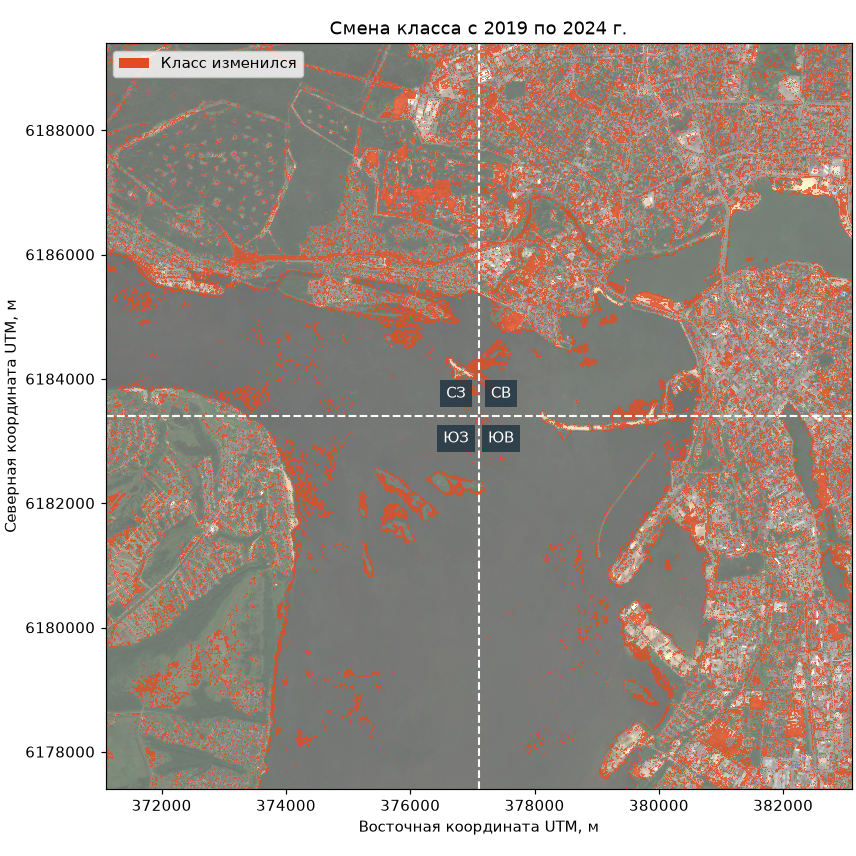

In [22]:
first = class_maps[2019]
last = class_maps[2024]
valid = (first != class_nodata) & (last != class_nodata)
changed = valid & (first != last)

with rasterio.open(class_paths[2019]) as src:
    dx, dy = src.res
pixel_ha = dx * dy / 10000

n_classes = len(class_names)
pairs = first[valid] * n_classes + last[valid]
matrix = np.bincount(pairs, minlength=n_classes ** 2).reshape(n_classes, n_classes)
matrix_ha = pd.DataFrame(
    matrix * pixel_ha,
    index=pd.Index(class_names, name="Класс в 2019 г."),
    columns=pd.Index(class_names, name="Класс в 2024 г.")
)
display(matrix_ha.round(2))

rows = []
for source in range(n_classes):
    for target in range(n_classes):
        if source != target and matrix[source, target] > 0:
            rows.append([class_names[source], class_names[target], matrix[source, target] * pixel_ha])
main_transitions = pd.DataFrame(rows, columns=["Из класса", "В класс", "Площадь, га"])
main_transitions = main_transitions.sort_values("Площадь, га", ascending=False)
display(main_transitions.head(5).round(2))

mid_row = first.shape[0] // 2
mid_col = first.shape[1] // 2
sector_slices = {
    "Северо-запад": (slice(0, mid_row), slice(0, mid_col)),
    "Северо-восток": (slice(0, mid_row), slice(mid_col, None)),
    "Юго-запад": (slice(mid_row, None), slice(0, mid_col)),
    "Юго-восток": (slice(mid_row, None), slice(mid_col, None))
}
rows = []
for name, area in sector_slices.items():
    total = np.count_nonzero(valid[area])
    count = np.count_nonzero(changed[area])
    share = np.nan
    if total > 0:
        share = count / total * 100
    rows.append([name, count * pixel_ha, share])
sectors = pd.DataFrame(rows, columns=["Часть ROI", "Изменилось, га", "Доля изменившихся, %"])
sectors = sectors.sort_values("Доля изменившихся, %", ascending=False)
display(sectors.round(2))
print(f"Сменили класс {np.count_nonzero(changed) * pixel_ha:.2f} га.")

background = np.dstack((reflectance[2024][2], reflectance[2024][1], reflectance[2024][0]))
background = np.clip(background / 0.30, 0, 1)
overlay = np.ma.masked_where(~changed, changed)
left, right, bottom, top = extents[2024]

fig, ax = plt.subplots(figsize=(8, 8), layout="constrained")
ax.imshow(background, extent=extents[2024], alpha=0.60)
ax.imshow(overlay, extent=extents[2024], cmap=ListedColormap(["#e04d24"]),
          vmin=0, vmax=1, interpolation="nearest", alpha=0.8)
ax.axvline((left + right) / 2, color="white", linestyle="--", linewidth=1.4)
ax.axhline((bottom + top) / 2, color="white", linestyle="--", linewidth=1.4)
quadrants = [("СЗ", 0.47, 0.53), ("СВ", 0.53, 0.53), ("ЮЗ", 0.47, 0.47), ("ЮВ", 0.53, 0.47)]
for name, x, y in quadrants:
    ax.text(x, y, name, transform=ax.transAxes, ha="center", va="center",
            color="white", bbox={"facecolor": "#233744", "edgecolor": "none", "alpha": 0.85})

ax.set_title("Смена класса с 2019 по 2024 г.")
ax.set_xlabel("Восточная координата UTM, м")
ax.set_ylabel("Северная координата UTM, м")
ax.ticklabel_format(style="plain", useOffset=False)
ax.legend(handles=[Patch(facecolor="#e04d24", label="Класс изменился")], loc="upper left")
plt.show()


## **7. Сравнение с картами Dynamic World**

### **7.1. Рассчитать площади всех классов для каждого года по картам классификации**



In [23]:
dw_pixel_counts = pd.DataFrame(index=dw_names).rename_axis("Класс")
for year in years:
    raster = dw_maps[year]
    valid = raster != dw_nodata
    dw_pixel_counts[year] = np.bincount(raster[valid], minlength=len(dw_names))

dw_areas_ha = areas_from_counts(dw_pixel_counts, dw_paths)
print(f"Площадь одного пикселя: {pixel_area_m2(dw_paths[2019]):g} м²")
print("Количество пикселей по классам и годам")
display(dw_pixel_counts)
show_areas(dw_areas_ha)
print("Распределение классов Dynamic World за 2024 год")
display(count_pixels(dw_maps[2024], dw_names, dw_nodata).round(3))


Площадь одного пикселя: 100 м²
Количество пикселей по классам и годам


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,583981,585199,585885,583958,574777,577043
Деревья,246235,270307,241355,277576,249297,256630
Трава,35780,23086,31054,12398,19180,19262
Затопленная растительность,6646,4749,6035,8455,10614,7823
Культуры,12682,8857,9724,9268,9393,8559
Кустарники,8931,6877,10889,3568,10161,5399
Застройка,534535,530649,545061,535699,554060,555381
Голая земля,11210,10266,9997,9078,12518,9903
Снег/лёд,0,10,0,0,0,0


Площади классов, га


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,5839.81,5851.99,5858.85,5839.58,5747.77,5770.43
Деревья,2462.35,2703.07,2413.55,2775.76,2492.97,2566.30
Трава,357.80,230.86,310.54,123.98,191.80,192.62
Затопленная растительность,66.46,47.49,60.35,84.55,106.14,78.23
Культуры,126.82,88.57,97.24,92.68,93.93,85.59
Кустарники,89.31,68.77,108.89,35.68,101.61,53.99
Застройка,5345.35,5306.49,5450.61,5356.99,5540.60,5553.81
Голая земля,112.10,102.66,99.97,90.78,125.18,99.03
Снег/лёд,0.00,0.10,0.00,0.00,0.00,0.00


Площади классов, км²


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,58.3981,58.5199,58.5885,58.3958,57.4777,57.7043
Деревья,24.6235,27.0307,24.1355,27.7576,24.9297,25.6630
Трава,3.5780,2.3086,3.1054,1.2398,1.9180,1.9262
Затопленная растительность,0.6646,0.4749,0.6035,0.8455,1.0614,0.7823
Культуры,1.2682,0.8857,0.9724,0.9268,0.9393,0.8559
Кустарники,0.8931,0.6877,1.0889,0.3568,1.0161,0.5399
Застройка,53.4535,53.0649,54.5061,53.5699,55.4060,55.5381
Голая земля,1.1210,1.0266,0.9997,0.9078,1.2518,0.9903
Снег/лёд,0.0000,0.0010,0.0000,0.0000,0.0000,0.0000


Доля от площади участка, %


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,40.554,40.639,40.686,40.553,39.915,40.072
Деревья,17.100,18.771,16.761,19.276,17.312,17.822
Трава,2.485,1.603,2.157,0.861,1.332,1.338
Затопленная растительность,0.462,0.330,0.419,0.587,0.737,0.543
Культуры,0.881,0.615,0.675,0.644,0.652,0.594
Кустарники,0.620,0.478,0.756,0.248,0.706,0.375
Застройка,37.120,36.851,37.851,37.201,38.476,38.568
Голая земля,0.778,0.713,0.694,0.630,0.869,0.688
Снег/лёд,0.000,0.001,0.000,0.000,0.000,0.000


Распределение классов Dynamic World за 2024 год


,Метка,Класс,Пикселей,"Доля учтённых пикселей, %"
0,0,Вода,577043,40.072
1,1,Деревья,256630,17.822
2,2,Трава,19262,1.338
3,3,Затопленная растительность,7823,0.543
4,4,Культуры,8559,0.594
5,5,Кустарники,5399,0.375
6,6,Застройка,555381,38.568
7,7,Голая земля,9903,0.688


### **7.2. Построить графики динамики изменений для каждого класса по картам классификации**



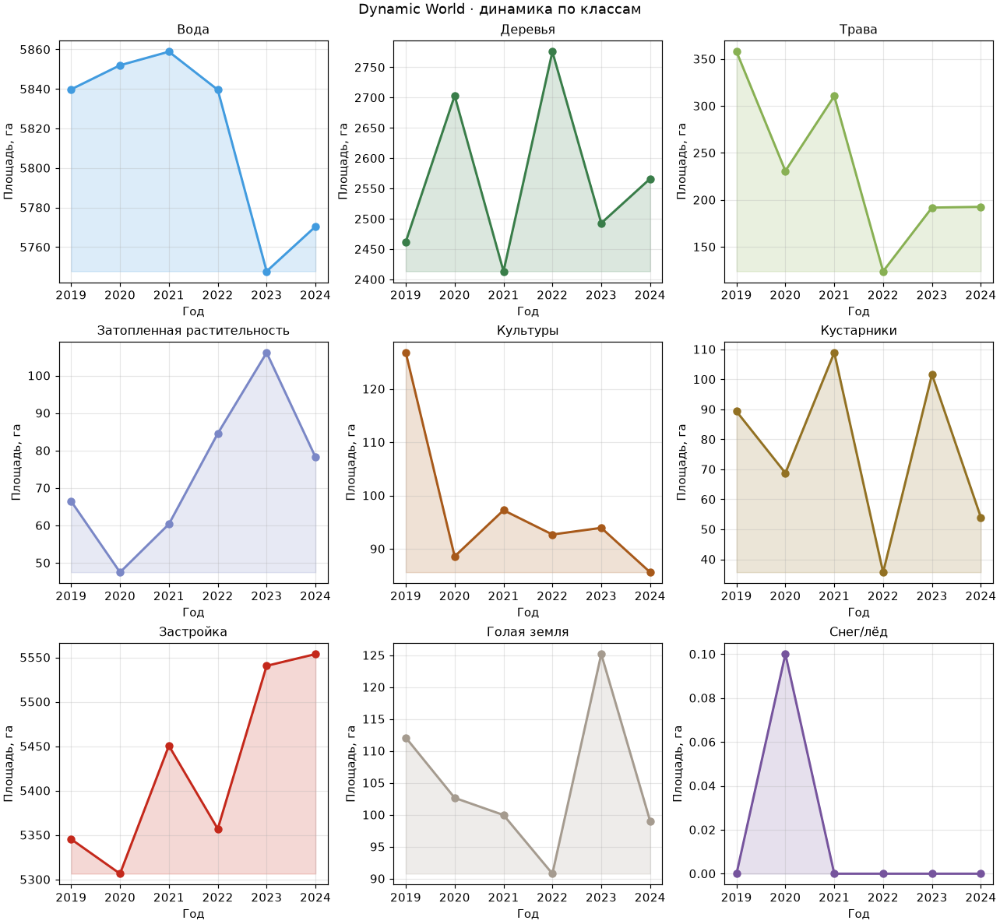

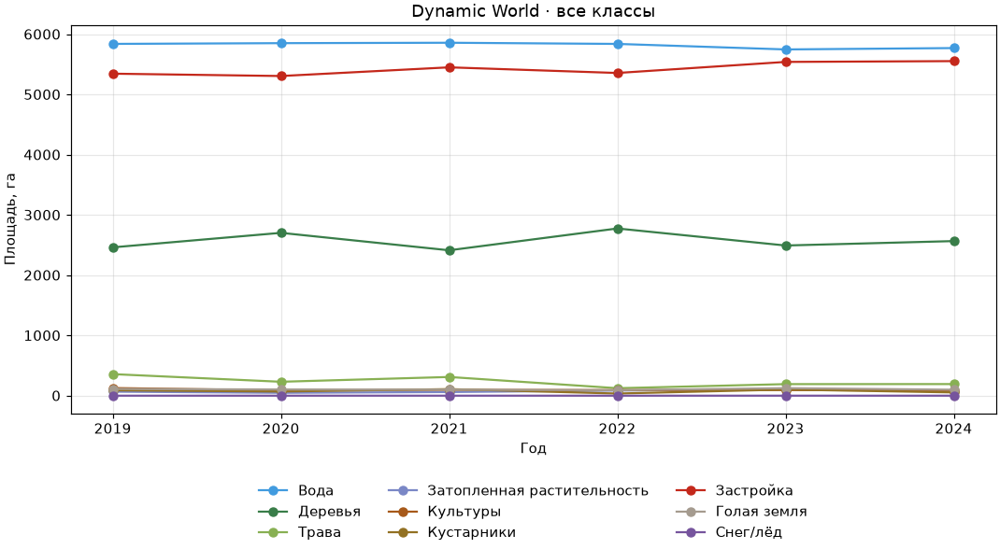

In [24]:
plot_dynamics(dw_areas_ha, dw_colors, "Dynamic World", 3)


### **7.3. Рассчитать все статистические показатели по картам классификации**



In [25]:
dw_changes = calculate_changes(dw_areas_ha)
display(dw_changes.round(3))


,"S₍₂₀₁₉₎, га","S₍₂₀₂₄₎, га","ΔS, га","Δ, %","Прирост, га/год","Темп, %/год","μ, га","σ, га","CV, %","Наклон, га/год",R²,Тренд
Класс,,,,,,,,,,,,
Вода,5839.81,5770.43,-69.38,-1.188,-13.876,-0.239,5818.072,42.741,0.735,-19.395,0.601,↓
Деревья,2462.35,2566.30,103.95,4.222,20.790,0.830,2569.000,130.417,5.077,7.190,0.009,→
Трава,357.80,192.62,-165.18,-46.165,-33.036,-11.649,234.600,78.305,33.378,-32.275,0.496,→
Затопленная растительность,66.46,78.23,11.77,17.710,2.354,3.315,73.870,18.744,25.374,7.400,0.455,→
Культуры,126.82,85.59,-41.23,-32.511,-8.246,-7.563,97.472,13.646,14.000,-5.561,0.484,→
Кустарники,89.31,53.99,-35.32,-39.548,-7.064,-9.576,76.375,26.065,34.128,-4.323,0.080,→
Застройка,5345.35,5553.81,208.46,3.900,41.692,0.768,5425.642,96.283,1.775,47.172,0.700,↑
Голая земля,112.10,99.03,-13.07,-11.659,-2.614,-2.449,104.953,11.002,10.483,-0.199,0.001,→
Снег/лёд,0.00,0.00,0.00,NaN,0.000,NaN,0.017,0.037,223.607,-0.009,0.154,→


### **7.4. Определить какие классы показали наибольшие изменения по картам классификации**



In [26]:
show_ranking(dw_changes)


Классы, прошедшие все три порога значимости
Таких классов нет.
Ранжирование по модулю относительного изменения


,"S₍₂₀₁₉₎, га","S₍₂₀₂₄₎, га","ΔS, га","Δ, %","Прирост, га/год","CV, %",R²
Класс,,,,,,,
Трава,357.80,192.62,-165.18,-46.165,-33.036,33.378,0.496
Кустарники,89.31,53.99,-35.32,-39.548,-7.064,34.128,0.080
Культуры,126.82,85.59,-41.23,-32.511,-8.246,14.000,0.484
Затопленная растительность,66.46,78.23,11.77,17.710,2.354,25.374,0.455
Голая земля,112.10,99.03,-13.07,-11.659,-2.614,10.483,0.001
Деревья,2462.35,2566.30,103.95,4.222,20.790,5.077,0.009
Застройка,5345.35,5553.81,208.46,3.900,41.692,1.775,0.700
Вода,5839.81,5770.43,-69.38,-1.188,-13.876,0.735,0.601
Снег/лёд,0.00,0.00,0.00,NaN,0.000,223.607,0.154


Наибольшее изменение в гектарах: Застройка, +208.46 га


### **7.5. Создать сводную таблицу результатов по картам классификации**



In [27]:
show_summary(dw_changes)


,"S₍₂₀₁₉₎, га","S₍₂₀₂₄₎, га","ΔS, га","Δ, %","Темп, %/год",Тренд,"CV, %",R²
Класс,,,,,,,,
Вода,5839.81,5770.43,-69.38,-1.188,-0.239,↓,0.735,0.601
Деревья,2462.35,2566.30,103.95,4.222,0.830,→,5.077,0.009
Трава,357.80,192.62,-165.18,-46.165,-11.649,→,33.378,0.496
Затопленная растительность,66.46,78.23,11.77,17.710,3.315,→,25.374,0.455
Культуры,126.82,85.59,-41.23,-32.511,-7.563,→,14.000,0.484
Кустарники,89.31,53.99,-35.32,-39.548,-9.576,→,34.128,0.080
Застройка,5345.35,5553.81,208.46,3.900,0.768,↑,1.775,0.700
Голая земля,112.10,99.03,-13.07,-11.659,-2.449,→,10.483,0.001
Снег/лёд,0.00,0.00,0.00,NaN,NaN,→,223.607,0.154


## **8. Сравнение результатов полученных по результатам сегментации и картам классификаций**

**Задание:** Сведите классы обоих методов к укрупнённым классам по таблице 10. Сравните площади укрупнённых классов по годам, рассчитайте долю совпадающих пикселей для каждого года и матрицу совпадений для 2024 года.

#### **Таблица 10. Соответствие классов сегментации и Dynamic World**

| **Укрупнённый класс** | **Метки сегментации** | **Классы Dynamic World** |
|---|---|---|
| Вода | 0 | 0 — Вода |
| Снег/лед | 1 | 8 — Снег и лед |
| Застройка | 2 | 6 — Застройка |
| Растительность | 3, 4, 5 | 1 — Деревья, 2 — Трава, 3 — Затопл. растительность, 4 — Культуры, 5 — Кустарники |
| Открытая почва | 6 | 7 — Голая земля |
| Прочее | 7 | — |

Площади укрупнённых классов по индексам, га


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,5322.14,5293.90,5493.61,5515.97,5366.90,5380.32
Снег/лёд,0.13,0.14,0.19,0.13,0.63,0.11
Застройка,1425.42,1483.98,1643.35,1624.11,1771.69,1645.10
Растительность,7380.14,7367.11,7114.83,7134.49,7117.55,7197.82
Открытая почва,94.84,110.20,91.98,79.56,93.54,96.32
Прочее,177.33,142.43,56.04,45.74,49.69,80.33


Площади укрупнённых классов по Dynamic World, га


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,5839.81,5851.39,5858.85,5839.58,5747.77,5770.43
Снег/лёд,0.00,0.10,0.00,0.00,0.00,0.00
Застройка,5345.35,5304.85,5450.61,5356.99,5540.60,5553.81
Растительность,3102.74,3138.76,2990.57,3112.65,2986.45,2976.73
Открытая почва,112.10,102.66,99.97,90.78,125.18,99.03
Прочее,0.00,0.00,0.00,0.00,0.00,0.00


Попиксельное совпадение на общей маске


,Сравнено пикселей,Совпало пикселей,"Совпадение, %","Сравнено от ROI, %"
Год,,,,
2019,1440000,959949,66.66,100.00
2020,1439776,964431,66.98,99.98
2021,1440000,988045,68.61,100.00
2022,1440000,1003645,69.70,100.00
2023,1440000,984609,68.38,100.00
2024,1440000,979041,67.99,100.00


Среднее годовое совпадение: 68.05%
Сравнение площадей, темпов роста и годовых рядов


,"Индексы 2019, га","DW 2019, га","Индексы 2024, га","DW 2024, га",Δ% по индексам,Δ% по DW,"Темп индексы, %/год","Темп DW, %/год",Корреляция рядов
Класс,,,,,,,,,
Вода,5322.14,5839.81,5380.32,5770.43,1.093,-1.188,0.218,-0.239,0.206
Снег/лёд,0.13,0.00,0.11,0.00,-15.385,NaN,-3.286,NaN,-0.198
Застройка,1425.42,5345.35,1645.10,5553.81,15.412,3.900,2.908,0.768,0.802
Растительность,7380.14,3102.74,7197.82,2976.73,-2.470,-4.061,-0.499,-0.826,0.665
Открытая почва,94.84,112.10,96.32,99.03,1.561,-11.659,0.310,-2.449,0.272
Прочее,177.33,0.00,80.33,0.00,-54.700,NaN,-14.647,NaN,NaN


Корреляция Пирсона приведена для рядов с меняющейся площадью.


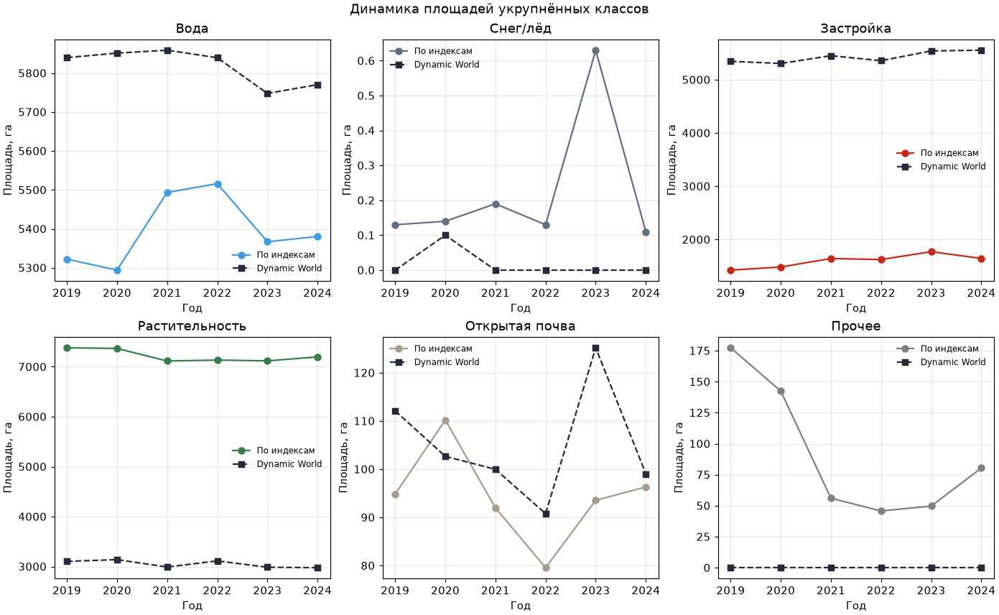

Матрица совпадений за 2024 год, пикселей


Dynamic World,Вода,Снег/лёд,Застройка,Растительность,Открытая почва,Прочее
По индексам,,,,,,
Вода,537706,0,211,115,0,0
Снег/лёд,7,0,2,2,0,0
Застройка,10703,0,144891,1216,7700,0
Растительность,22428,0,398991,296302,2061,0
Открытая почва,1945,0,7539,6,142,0
Прочее,4254,0,3747,32,0,0


Наиболее частые расхождения за 2024 год


,По индексам,Dynamic World,Пикселей
0,Растительность,Застройка,398991
1,Растительность,Вода,22428
2,Застройка,Вода,10703
3,Застройка,Открытая почва,7700
4,Открытая почва,Застройка,7539


In [28]:
group_names = ["Вода", "Снег/лёд", "Застройка", "Растительность", "Открытая почва", "Прочее"]
group_colors = ["#419bdf", "#626f81", "#c4281b", "#397d49", "#a59b8f", "#808080"]
index_lookup = np.array([0, 1, 2, 3, 3, 3, 4, 5])
dw_lookup = np.array([0, 3, 3, 3, 3, 3, 2, 4, 1])
n_groups = len(group_names)

index_group_areas = pd.DataFrame(index=group_names).rename_axis("Класс")
dw_group_areas = pd.DataFrame(index=group_names).rename_axis("Класс")
agreement_rows = []

for year in years:
    index_map = class_maps[year]
    dw_map = dw_maps[year]
    valid = (index_map != class_nodata) & (dw_map != dw_nodata)
    index_groups = index_lookup[index_map[valid]]
    dw_groups = dw_lookup[dw_map[valid]]
    pairs = index_groups * n_groups + dw_groups
    counts = np.bincount(pairs, minlength=n_groups ** 2).reshape(n_groups, n_groups)

    pixel_ha = pixel_area_m2(class_paths[year]) / 10000
    index_group_areas[year] = counts.sum(axis=1) * pixel_ha
    dw_group_areas[year] = counts.sum(axis=0) * pixel_ha

    total = counts.sum()
    matches = counts.trace()
    agreement_rows.append([year, total, matches, matches / total * 100,
                           total * pixel_ha / roi_area_ha * 100])

agreement = pd.DataFrame(
    agreement_rows, columns=["Год", "Сравнено пикселей", "Совпало пикселей",
                             "Совпадение, %", "Сравнено от ROI, %"]
)
confusion = pd.DataFrame(
    counts, index=pd.Index(group_names, name="По индексам"),
    columns=pd.Index(group_names, name="Dynamic World")
)

print("Площади укрупнённых классов по индексам, га")
display(index_group_areas.round(2))
print("Площади укрупнённых классов по Dynamic World, га")
display(dw_group_areas.round(2))
print("Попиксельное совпадение на общей маске")
display(agreement.set_index("Год").round(2))
print(f"Среднее годовое совпадение: {agreement['Совпадение, %'].mean():.2f}%")

index_stats = calculate_changes(index_group_areas)
dw_stats = calculate_changes(dw_group_areas)
correlations = []
for name in group_names:
    index_values = index_group_areas.loc[name]
    dw_values = dw_group_areas.loc[name]
    correlation = np.nan
    if index_values.nunique() > 1 and dw_values.nunique() > 1:
        correlation = index_values.corr(dw_values)
    correlations.append(correlation)

comparison = pd.DataFrame({
    "Индексы 2019, га": index_group_areas[2019],
    "DW 2019, га": dw_group_areas[2019],
    "Индексы 2024, га": index_group_areas[2024],
    "DW 2024, га": dw_group_areas[2024],
    "Δ% по индексам": index_stats["Δ, %"],
    "Δ% по DW": dw_stats["Δ, %"],
    "Темп индексы, %/год": index_stats["Темп, %/год"],
    "Темп DW, %/год": dw_stats["Темп, %/год"],
    "Корреляция рядов": correlations
})
print("Сравнение площадей, темпов роста и годовых рядов")
display(comparison.round(3))
print("Корреляция Пирсона приведена для рядов с меняющейся площадью.")

fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout="constrained")
fig.suptitle("Динамика площадей укрупнённых классов")
for ax, name, color in zip(axes.flat, group_names, group_colors):
    ax.plot(years, index_group_areas.loc[name], "-o", color=color, label="По индексам")
    ax.plot(years, dw_group_areas.loc[name], "--s", color="#25293a", label="Dynamic World")
    ax.set_title(name)
    ax.set_xlabel("Год")
    ax.set_ylabel("Площадь, га")
    ax.set_xticks(years)
    ax.grid(alpha=0.3)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    ax.legend(fontsize=8, frameon=False)
plt.show()

print("Матрица совпадений за 2024 год, пикселей")
display(confusion)

rows = []
for index_label in range(n_groups):
    for dw_label in range(n_groups):
        if index_label != dw_label and counts[index_label, dw_label] > 0:
            rows.append([group_names[index_label], group_names[dw_label], counts[index_label, dw_label]])
disagreements = pd.DataFrame(rows, columns=["По индексам", "Dynamic World", "Пикселей"])
disagreements = disagreements.sort_values("Пикселей", ascending=False)
print("Наиболее частые расхождения за 2024 год")
display(disagreements.head(5).reset_index(drop=True))


## **9. Выводы**

В выводах обязательно отразить:
1. **Количественная оценка динамики** (с конкретными цифрами для каждого класса)
2. **Выявленные тренды** (растущие, убывающие, стабильные классы)
3. **Скорость изменений** (га/год и %/год для ключевых классов)
4. **Пространственные закономерности** (где происходят основные изменения)
5. **Согласованность методов** (доля совпадающих пикселей по укрупнённым классам в % и основные причины расхождений)

### Пороговая сегментация Sentinel-2

| Класс | 2019, га | 2024, га | ΔS, га | Прирост, га/год | Темп, %/год | Тренд |
|---|---:|---:|---:|---:|---:|:---:|
| Вода | 5 322,14 | 5 380,32 | +58,18 | +11,64 | +0,22 | → |
| Снег/лёд | 0,13 | 0,11 | −0,02 | 0,00 | −3,29 | → |
| Застройка | 1 425,42 | 1 645,10 | +219,68 | +43,94 | +2,91 | ↑ |
| Густая растительность | 4 169,78 | 3 913,54 | −256,24 | −51,25 | −1,26 | → |
| Умеренная растительность | 2 320,64 | 2 341,25 | +20,61 | +4,12 | +0,18 | → |
| Разреженная растительность | 889,72 | 943,03 | +53,31 | +10,66 | +1,17 | → |
| Открытая почва | 94,84 | 96,32 | +1,48 | +0,30 | +0,31 | → |
| Прочее | 177,33 | 80,33 | −97,00 | −19,40 | −14,65 | ↓ |

Рост площади отмечен у следующих классов — «Застройка». Снижение площади отмечено у следующих классов — «Прочее». Без выраженного тренда остались классы «Вода», «Снег/лёд», «Густая растительность», «Умеренная растительность», «Разреженная растительность», «Открытая почва».
Всем трём критериям значимого изменения из §6.4 соответствуют классы «Застройка», «Прочее».

В 2024 г. пороговая сегментация отнесла к снегу и льду 11 пикселей (0,11 га). Dynamic World в этом году дал нулевую площадь класса. Для летних снимков Казани эти единичные метки следует считать вероятной ошибкой классификации.

### Dynamic World

| Класс | 2019, га | 2024, га | ΔS, га | Прирост, га/год | Темп, %/год | Тренд |
|---|---:|---:|---:|---:|---:|:---:|
| Вода | 5 839,81 | 5 770,43 | −69,38 | −13,88 | −0,24 | ↓ |
| Деревья | 2 462,35 | 2 566,30 | +103,95 | +20,79 | +0,83 | → |
| Трава | 357,80 | 192,62 | −165,18 | −33,04 | −11,65 | → |
| Затопленная растительность | 66,46 | 78,23 | +11,77 | +2,35 | +3,31 | → |
| Культуры | 126,82 | 85,59 | −41,23 | −8,25 | −7,56 | → |
| Кустарники | 89,31 | 53,99 | −35,32 | −7,06 | −9,58 | → |
| Застройка | 5 345,35 | 5 553,81 | +208,46 | +41,69 | +0,77 | ↑ |
| Голая земля | 112,10 | 99,03 | −13,07 | −2,61 | −2,45 | → |
| Снег/лёд | 0,00 | 0,00 | 0,00 | 0,00 | — | → |

Рост площади отмечен у следующих классов — «Застройка». Снижение площади отмечено у следующих классов — «Вода». Без выраженного тренда остались классы «Деревья», «Трава», «Затопленная растительность», «Культуры», «Кустарники», «Голая земля», «Снег/лёд».
Ни один класс не преодолел все три порога значимого изменения из §6.4.

Стрелка → показывает постоянную площадь или межгодовые колебания при R² < 0,5. Тире в столбце темпа означает, что в 2019 году площадь была нулевой.

### Где менялись классы

По пороговой сегментации пиксели, сменившие класс между 2019 и 2024 гг., занимают **2 463,26 га** на общей маске двух лет. Доля изменившихся пикселей выше всего в секторе «северо-восток» (25,13%, 904,72 га). В секторе «юго-восток» она составила 17,64%. На карте в §6.6 видны скопления изменений вдоль берегов Волги и в городской части на северо-востоке.

Преобладают переходы «густая растительность → умеренная растительность» (521,26 га) и «умеренная растительность → густая растительность» (357,34 га). Переходы между классами густоты растительности могут зависеть от фазы развития растений и летних условий съёмки.

### Согласованность методов

Совпадение укрупнённых классов на общей маске по годам составило 2019 — 66,66%, 2020 — 66,98%, 2021 — 68,61%, 2022 — 69,70%, 2023 — 68,38%, 2024 — 67,99%. Среднее годовое совпадение за шесть лет — 68,05%. В 2024 г. сравнение охватило 1 440 000 пикселей. Чаще всего пороговая сегментация определяла «растительность», а Dynamic World — «застройка» (398 991 пикселей). Следующим по частоте было расхождение «растительность / вода» (22 428 пикселей).

По общей маске 2024 г. оценки застройки составили 1 645,10 и 5 553,81 га, оценки открытой почвы — 96,32 и 99,03 га соответственно. Оба метода показали рост площади застройки с 2019 по 2024 г. примерно на 200 га (219,68 и 208,46 га). Из-за разной начальной площади относительный рост составил 15,41% по индексам и 3,90% по Dynamic World.

На участках смешанной городской застройки растительность может повышать NDVI выше порога для класса «Застройка». Модель Dynamic World учитывает пространственный контекст, что помогает объяснить основное расхождение. Сухая почва и пашня, наоборот, могут удовлетворять условию для застройки при высоком NDBI и низком NDVI. На сравнение также влияют разные способы объединения летних сцен и разные исходные классы растительности. Сравнение показывает согласованность двух карт. Для оценки точности каждого метода нужны независимые эталонные данные.

Данные Dynamic World подготовлены Google совместно с National Geographic Society и World Resources Institute. [Описание набора данных](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_DYNAMICWORLD_V1).
